# Generalized linear models

_Authors: Paul Bürkner, Lars Kühmichel, Stefan T. Radev_

## Introduction

We will estimate a Gaussian generalized linear model with two predictors, a sinusoidal feature, an interaction, and predictor-dependent noise. The mean is linear in the regression coefficients, with an identity link and known variance weights.

This is the same model used in [Foundation models as backbones](Foundation_Models.ipynb). Here, we learn a summary network jointly with the posterior estimator. That notebook replaces the summary network with pretrained embeddings.

We keep the usual workflow: define a simulator, build an adapter, train the networks, and check the posterior. Training covers different numbers of observations, so one estimator can handle datasets of different sizes. We prefer the `torch` backend, as naively passing dynamic batch sizes through JAX triggers recompilation and can be slow in early epochs.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [2]:
import numpy as np
from pathlib import Path

import bayesflow as bf

INFO:bayesflow:Using backend 'torch'


When using torch backend, we need to disable autograd by default to avoid excessive memory usage. Use

with torch.enable_grad():
    ...

in contexts where you need gradients (e.g. custom training loops).


BayesFlow separates simulation, preprocessing, and inference:

- `simulators` combine priors, likelihoods, and context variables.
- `adapters` prepare data for the networks.
- `networks` provide summary and inference architectures.
- `estimators` connect the networks and define their training objectives.

A `BasicWorkflow` brings these pieces together.

In [3]:
# avoid scientific notation for outputs
np.set_printoptions(suppress=True)

## Generative model

For two predictors $x_1,x_2$, our model is

$$y_i = \beta_0 + \beta_1\sin(1.5x_{i1}) + \beta_2x_{i1}x_{i2} + 0.5x_{i2} + \epsilon_i,$$
$$\epsilon_i \sim \mathcal N\!\left(0, [\sigma(1+0.4|x_{i2}|)]^2\right).$$

The $0.5x_2$ term is a known offset. We infer three coefficients and the noise scale $\sigma$. The foundation-model example uses the equivalent parameter $\ell=\log\sigma$.

We use the same fixed 100-row predictor table as that example. A dataset with $N$ observations uses its first $N$ rows.

We will start with our data simulator: 

In [4]:
rng = np.random.default_rng(2026)

design = rng.uniform(-2, 2, size=(100, 2))


def likelihood(beta, sigma, N):
    x = design[:N]
    mean = beta[0] + beta[1] * np.sin(1.5 * x[:, 0]) + beta[2] * x[:, 0] * x[:, 1] + 0.5 * x[:, 1]
    scale = sigma * (1 + 0.4 * np.abs(x[:, 1]))
    y = rng.normal(mean, scale)
    return dict(y=y, x=x)

The likelihood takes the coefficients `beta`, the noise scale `sigma`, and the number of observations `N`. Each row contains two predictor values and one response.

In [5]:
data_draws = likelihood(beta=[0.3, 1.0, -0.5], sigma=0.6, N=3)
print(data_draws["x"].shape, data_draws["y"].shape)

(3, 2) (3,)


Next, we define our prior simulator to sample draws of the model parameters `beta` and `sigma`:

In [6]:
def prior():
    beta = rng.normal([0, 0, 0], [0.7, 0.8, 0.6])
    sigma = np.float32(rng.lognormal(mean=-0.5, sigma=0.3))
    return dict(beta=beta, sigma=sigma)

In [7]:
prior_draws = prior()
print(prior_draws["beta"].shape)
print(prior_draws["beta"])

(3,)
[0.54466904 0.21256238 0.12237344]


We train over sample sizes from 20 to 100. The `meta` function draws one sample size per batch, so all datasets within that batch have the same shape.

In [8]:
def meta():
    return dict(N=rng.integers(20, 101))

In [9]:
meta_draws = meta()
print(meta_draws["N"])

53


Combine the prior, likelihood, and sample-size distribution:

In [10]:
simulator = bf.make_simulator([prior, likelihood], meta_fn=meta)

Let's draw a batch of 500 datasets:

In [11]:
sim_draws = simulator.sample(500)
print("N:", sim_draws["N"])
print({key: sim_draws[key].shape for key in ["beta", "sigma", "x", "y"]})

N: 37
{'beta': (500, 3), 'sigma': (500, 1), 'x': (500, 37, 2), 'y': (500, 37)}


Let's define the parameter key and corresponding names of individual parameters for easy filtering and plotting down the line.

In [12]:
par_keys = ["beta", "sigma"]
par_names = [r"$\beta_0$", r"$\beta_1$", r"$\beta_2$", r"$\sigma$"]

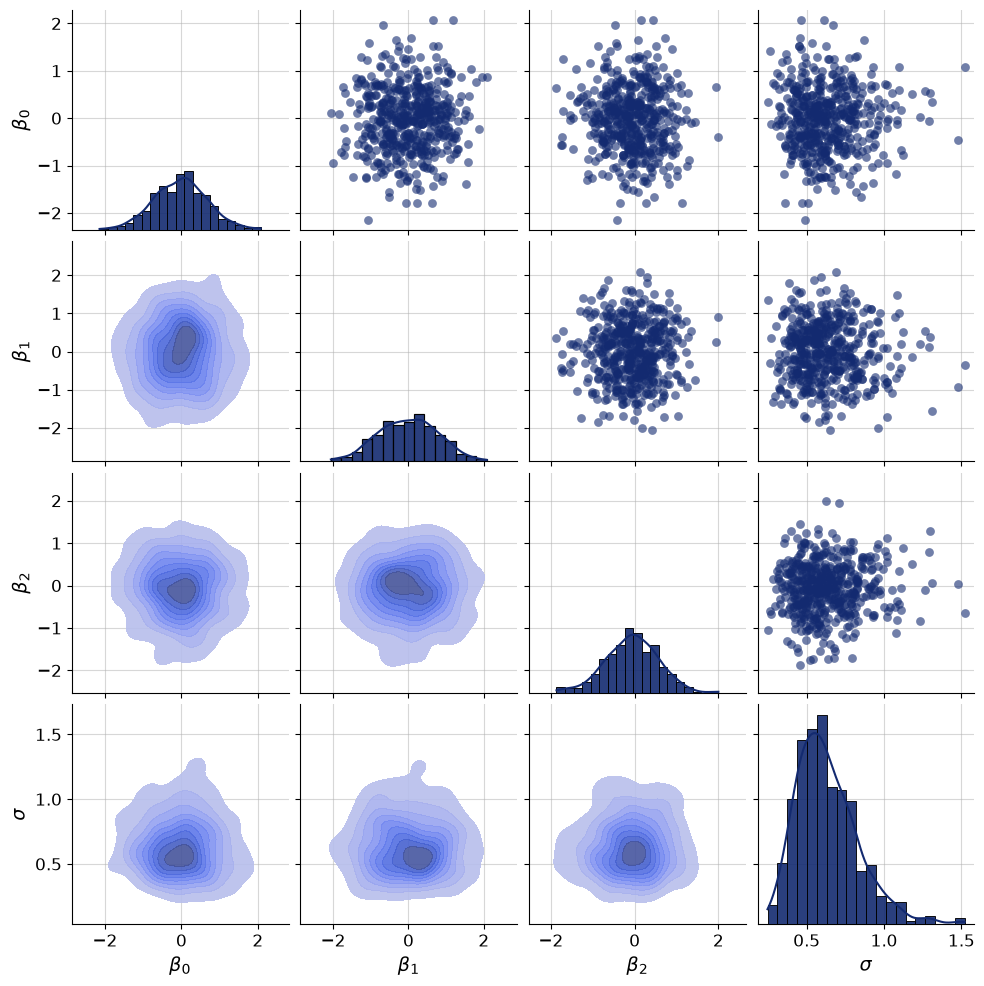

In [13]:
f = bf.diagnostics.pairs_samples(
    samples=sim_draws,
    variable_keys=par_keys,
    variable_names=par_names
)

## Adapter

The adapter collects the parameters into `inference_variables`, the observation rows into `summary_variables`, and the sample size into `inference_conditions`.

In [14]:
adapter = (
    bf.Adapter()
    .broadcast("N", to="y")
    .as_set(["x", "y"])
    .constrain("sigma", lower=0)
    .sqrt("N")
    .concatenate(["beta", "sigma"], into="inference_variables")
    .concatenate(["x", "y"], into="summary_variables")
    .rename("N", "inference_conditions")
)

The adapter broadcasts the batch's scalar `N`, then uses $\sqrt{N}$ as a condition. `as_set` gives the response a feature axis so it can be concatenated with the two predictors. The summary network handles joint permutations of the observation rows.

`constrain("sigma", lower=0)` maps the positive noise scale to an unconstrained training space and maps posterior samples back to positive values.

In [15]:
processed_draws = adapter(sim_draws)
print(processed_draws["summary_variables"].shape)
print(processed_draws["inference_conditions"].shape)
print(processed_draws["inference_variables"].shape)

torch.Size([500, 37, 3])
torch.Size([500, 1])
torch.Size([500, 4])


The processed shapes are:

- `summary_variables`: `(500, N, 3)` for two predictors and one response.
- `inference_conditions`: `(500, 1)` for the sample size.
- `inference_variables`: `(500, 4)` for three coefficients and the noise scale.

## Neural estimator

The summary network compresses each dataset into a vector. The inference network uses that vector and the sample size to approximate the parameter posterior.

### Summary network

A `SetTransformer` respects the fact that jointly reordering the predictor–response rows does not change the posterior. It maps `(batch_size, N, 3)` to `(batch_size, summary_dim)`. We use a small network with 16 summary features.

In [16]:
summary_network = bf.networks.SetTransformer(summary_dim=16, embed_dims=(32, 32), num_heads=(2, 2))

### Inference network

A two-layer spline coupling flow models the four-dimensional posterior.

In [17]:
inference_network = bf.networks.CouplingFlow(depth=2, transform="spline", subnet_kwargs={"widths": [64, 64]})

### Workflow

Workflow objects make life easier by combining inference networks and summary networks into estimators (internally).

In [18]:
workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=summary_network,
    standardize="all",
    initial_learning_rate=1e-3
)

We train on simulations generated during each epoch and monitor a separate validation batch. Torch handles the changing sample sizes without the shape-dependent recompilation encountered with JAX.

In [19]:
history = workflow.fit_online(epochs=60, batch_size=64, num_batches_per_epoch=100, validation_data=256, verbose=2)

INFO:bayesflow:Fitting on dataset instance of OnlineDataset.


INFO:bayesflow:Building on a test batch.


INFO:bayesflow:Training completed in 5.24 minutes.


Epoch 1/60
100/100 - 8s - 76ms/step - loss: 4.9383 - val_loss: 3.2981
Epoch 2/60
100/100 - 6s - 62ms/step - loss: 2.8052 - val_loss: 1.9665
Epoch 3/60
100/100 - 6s - 64ms/step - loss: 2.0253 - val_loss: 0.6803
Epoch 4/60
100/100 - 6s - 61ms/step - loss: 1.7459 - val_loss: 0.2184
Epoch 5/60
100/100 - 6s - 61ms/step - loss: 1.1599 - val_loss: 0.2523
Epoch 6/60
100/100 - 6s - 63ms/step - loss: 0.9701 - val_loss: -2.4383e-01
Epoch 7/60
100/100 - 6s - 59ms/step - loss: 0.9402 - val_loss: -1.0082e-01
Epoch 8/60
100/100 - 6s - 58ms/step - loss: 0.7201 - val_loss: -1.0748e-01
Epoch 9/60
100/100 - 6s - 60ms/step - loss: 0.6728 - val_loss: -5.2487e-01
Epoch 10/60
100/100 - 6s - 58ms/step - loss: 0.6926 - val_loss: -6.2547e-01
Epoch 11/60
100/100 - 6s - 56ms/step - loss: 0.7346 - val_loss: -3.3659e-01
Epoch 12/60
100/100 - 6s - 57ms/step - loss: 0.6113 - val_loss: -5.5821e-01
Epoch 13/60
100/100 - 6s - 56ms/step - loss: 0.5577 - val_loss: -5.6818e-01
Epoch 14/60
100/100 - 6s - 57ms/step - loss: 0

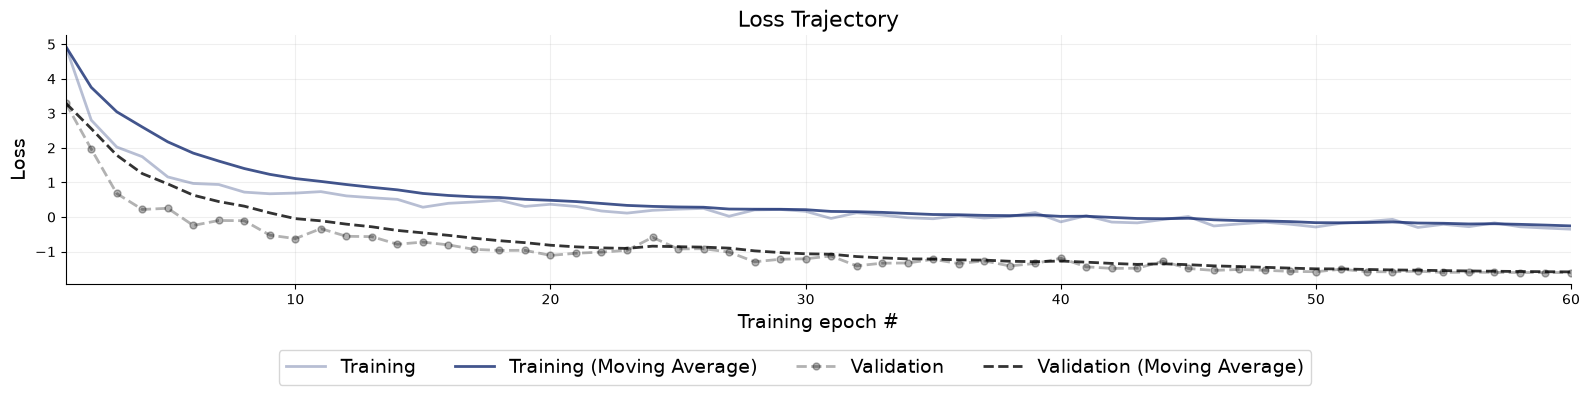

In [20]:
f = bf.diagnostics.loss(history)

## Diagnostics

Draw posterior samples for 200 test datasets. These were not used to train the estimator or monitor validation loss.

In [21]:
num_samples = 500
val_sims = simulator.sample(200)
post_draws = workflow.sample(conditions=val_sims, num_samples=num_samples)
post_draws.keys()

INFO:bayesflow:Sampling completed in 0.12 seconds.


dict_keys(['beta', 'sigma'])

In [22]:
print(post_draws["beta"].shape)

(200, 500, 3)


`post_draws["beta"]` has shape `(200, 500, 3)`: datasets, posterior draws, and regression coefficients.

In [23]:
post_draws["sigma"].min()

np.float32(0.20866281)

The adapter maps posterior samples of `sigma` back to its positive domain.

First, inspect the joint posterior for one dataset:

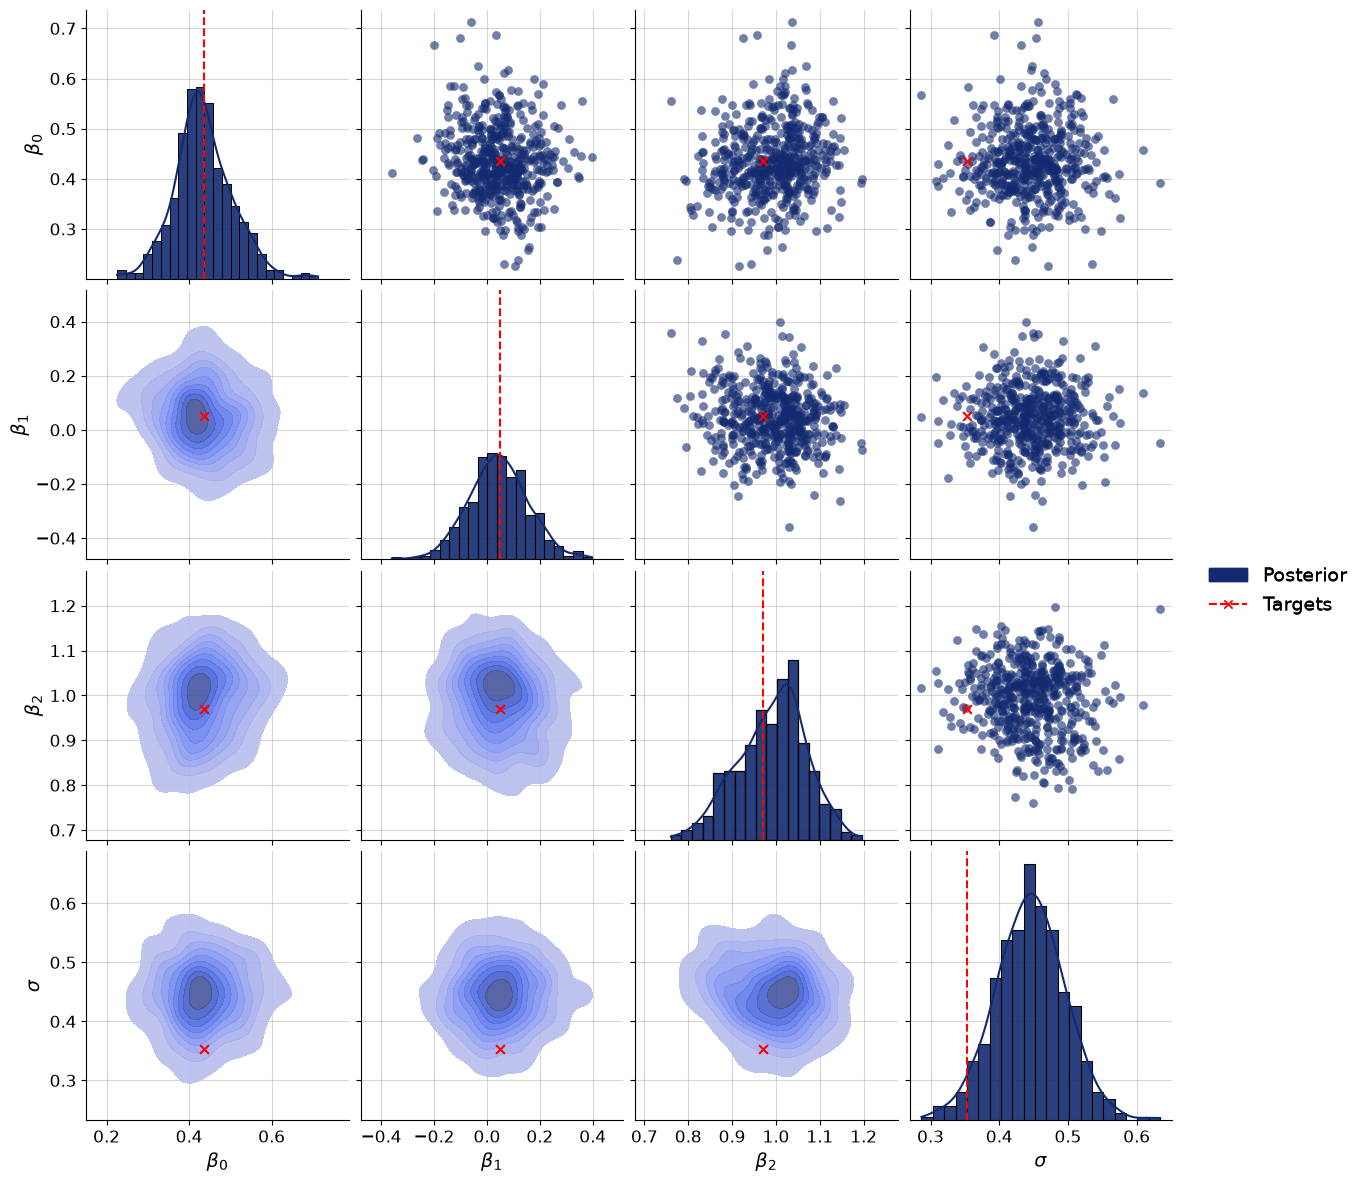

In [24]:
f = bf.diagnostics.pairs_posterior(
    estimates=post_draws, 
    targets=val_sims,
    dataset_id=0,
    variable_names=par_names,
)

Next, check parameter recovery across the test datasets. This batch has one sample size; repeat the check at other sizes when assessing the full training range.

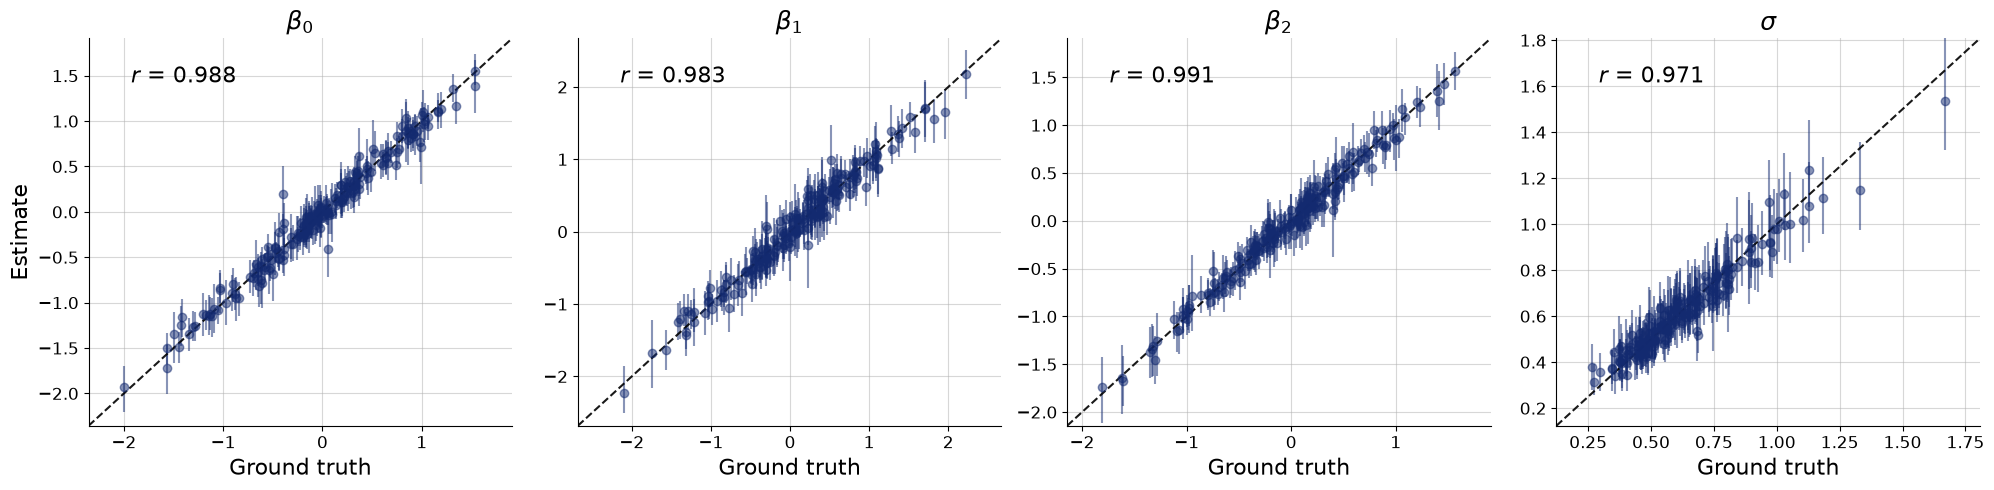

In [25]:
f = bf.diagnostics.recovery(
    estimates=post_draws, 
    targets=val_sims,
    variable_names=par_names
)

Parameter recovery alone does not establish calibration. In simulation-based calibration (SBC), parameters are drawn from the prior and data from the likelihood. A calibrated posterior produces uniform ranks for these parameter draws among posterior samples.

BayesFlow can display the rank distribution as histograms:

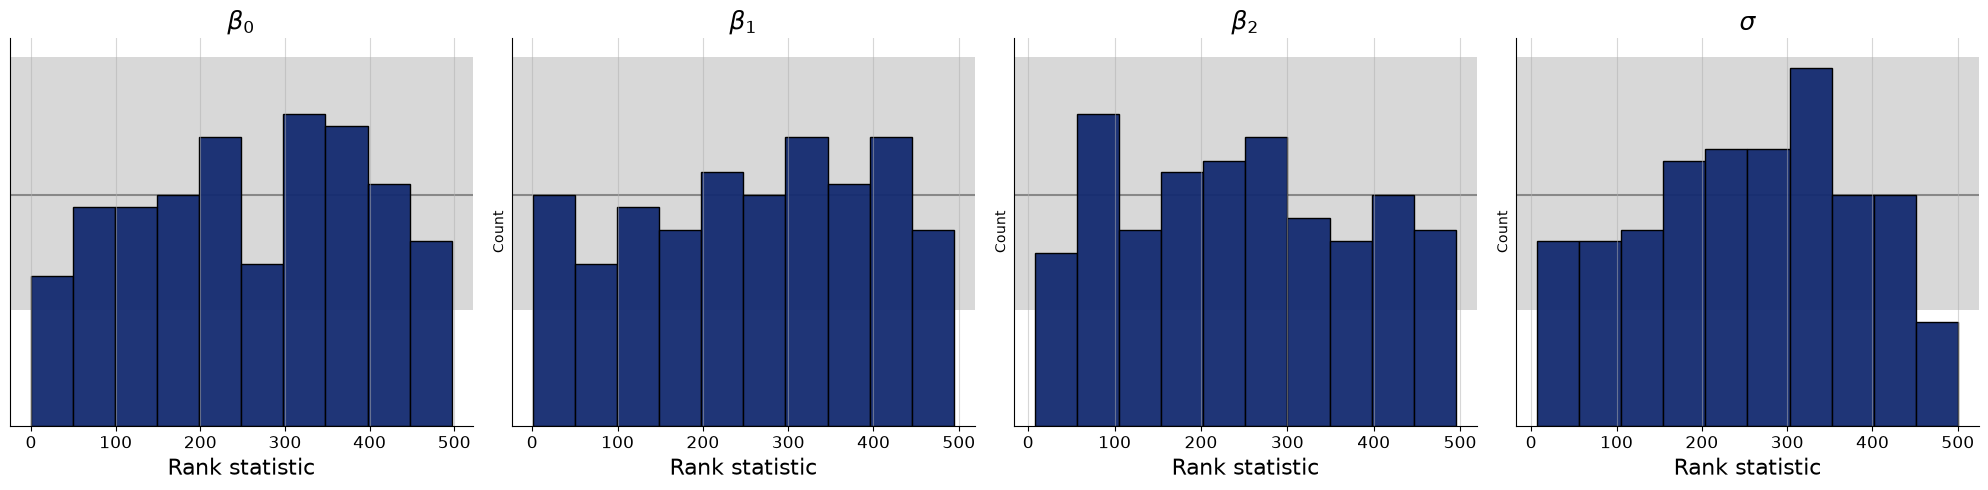

In [26]:
f = bf.diagnostics.calibration_histogram(
    estimates=post_draws, 
    targets=val_sims,
    variable_names=par_names
)

An ECDF plot makes systematic deviations easier to see. The shaded region shows the expected sampling variation under uniform ranks.

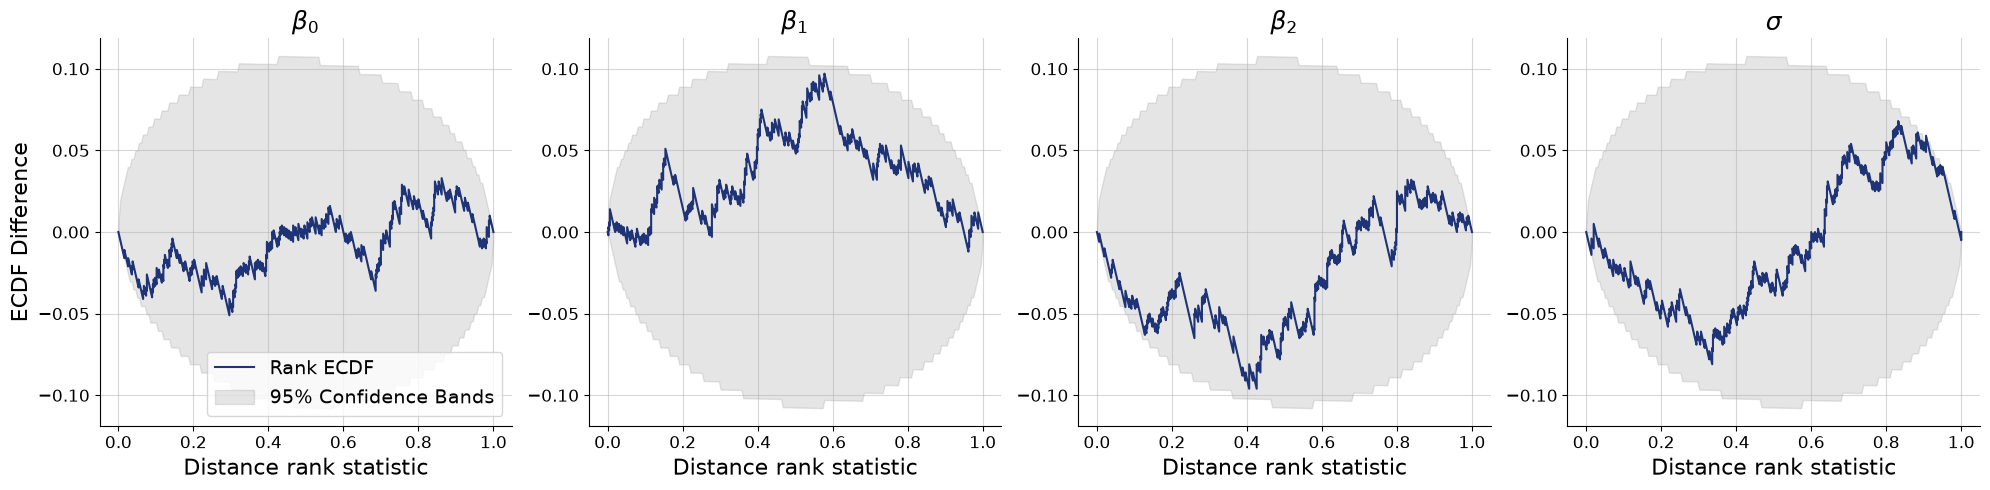

In [27]:
f = bf.diagnostics.calibration_ecdf(
    estimates=post_draws, 
    targets=val_sims,
    variable_names=par_names,
    difference=True,
    rank_type="distance"
)

### Custom test quantities for SBC

SBC also applies to functions of the parameters, including functions that depend on the observations. The joint log likelihood can reveal errors that marginal parameter checks miss.

Our Gaussian model has an analytic likelihood. The function below accepts batched parameters and observations and returns one log-likelihood value per dataset.

In [28]:
def joint_log_likelihood(data):
    beta, sigma, x, y = (data[key] for key in ["beta", "sigma", "x", "y"])
    mean = (beta[:, 0:1] + beta[:, 1:2] * np.sin(1.5 * x[..., 0])
            + beta[:, 2:3] * x[..., 0] * x[..., 1] + 0.5 * x[..., 1])
    scale = sigma * (1 + 0.4 * np.abs(x[..., 1]))
    return np.sum(-0.5 * ((y - mean) / scale)**2 - np.log(scale) - 0.5 * np.log(2 * np.pi), axis=-1)

In [29]:
joint_log_likelihood(val_sims).shape

(200,)

Repeat the observations along the posterior-sample axis so each draw can be paired with its dataset.

In [30]:
val_sims_conditions = {
    key: np.repeat(val_sims[key][:, None], num_samples, axis=1)
    for key in ["x", "y"]
}
post_draws_conditions = post_draws | val_sims_conditions

In [31]:
for key, arr in post_draws_conditions.items():
    print(f"Shape of {key}: {arr.shape}")

Shape of beta: (200, 500, 3)
Shape of sigma: (200, 500, 1)
Shape of x: (200, 500, 91, 2)
Shape of y: (200, 500, 91)


We check both the sum of the first two coefficients and the joint log likelihood:

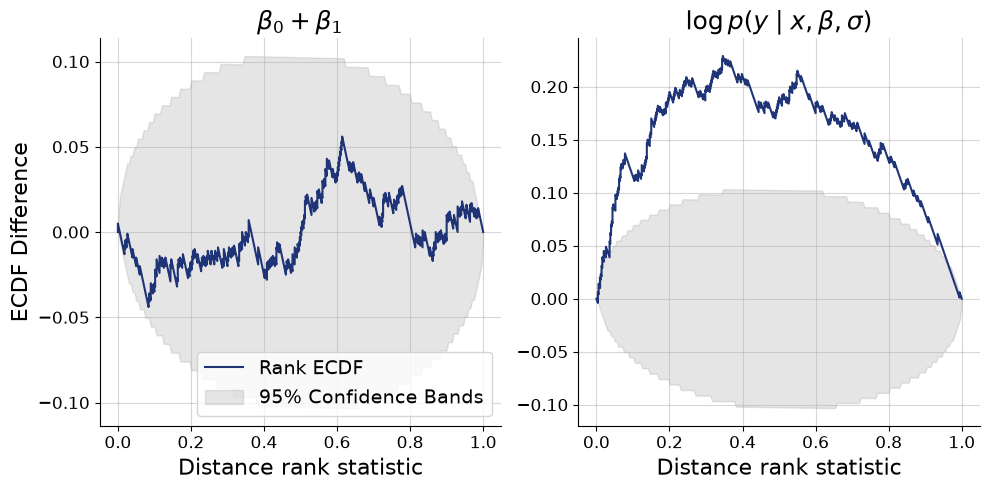

In [32]:
f = bf.diagnostics.calibration_ecdf(
    estimates=post_draws_conditions,
    targets=val_sims,
    test_quantities={
        r"$\beta_0 + \beta_1$": lambda data: data["beta"][:, :2].sum(axis=-1),
        r"$\log p(y\mid x,\beta,\sigma)$": joint_log_likelihood,
    },
    variable_keys=[],
    difference=True,
    rank_type="distance",
)

The joint-likelihood diagnostic is demanding: it can detect small errors shared across parameters. Use the plots to decide whether more training or a different summary network is needed.

### Checking Posterior Concentration

Posterior contraction measures the reduction in variance relative to the prior. The z-score measures the distance between the posterior mean and the generating parameter, in posterior standard deviations. We show the three regression coefficients.

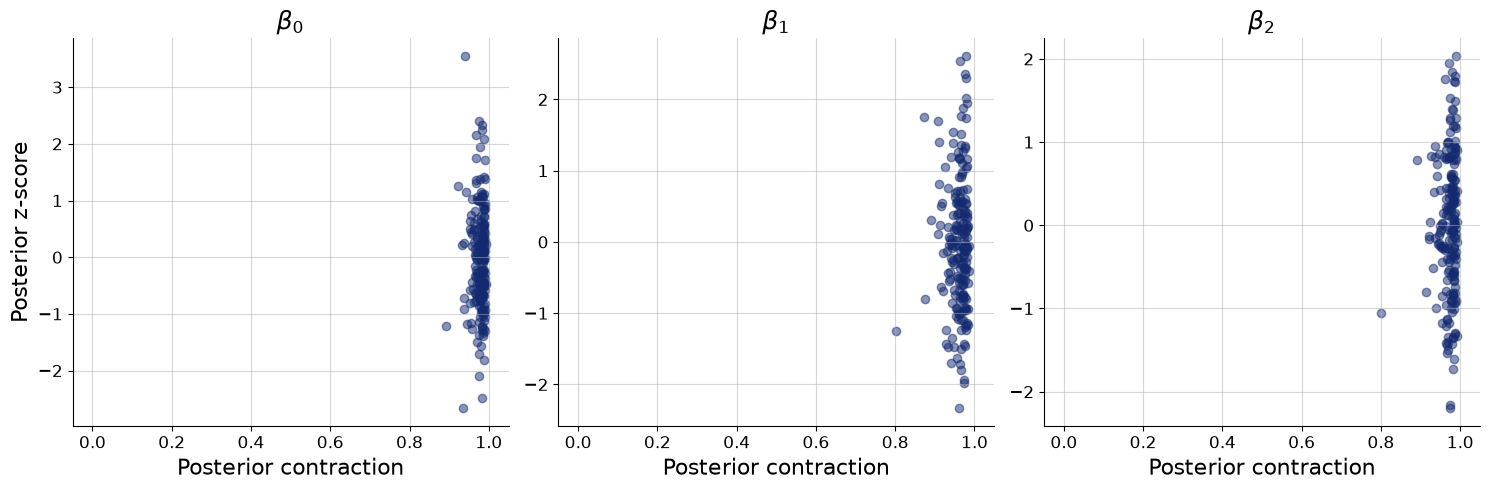

In [33]:
f = bf.diagnostics.z_score_contraction(
    estimates=post_draws,
    targets=val_sims,
    variable_keys=["beta"],
    variable_names=par_names[:3],
)

Strong contraction indicates that the data are informative. Large absolute z-scores can indicate a poorly approximated posterior and should be considered alongside the calibration plots.

### Saving and Loading the Trained Networks

Save the full estimator, including its adapter and standardization statistics:

In [34]:
filepath = Path("checkpoints") / "glm.keras"
filepath.parent.mkdir(exist_ok=True)
workflow.estimator.save(filepath)

For loading, we then use:

In [35]:
import keras

estimator = keras.saving.load_model(filepath)

The loaded estimator supports the same sampling and diagnostic calls:

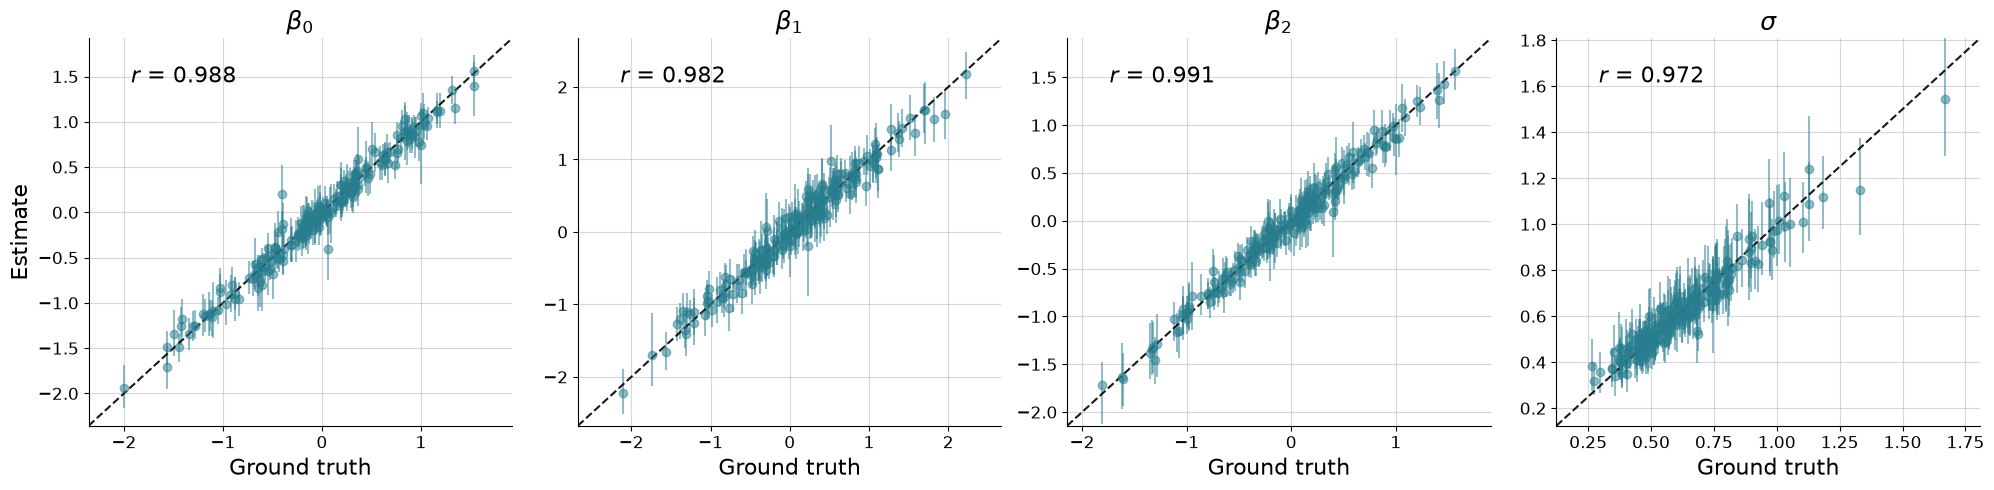

In [36]:
post_draws = estimator.sample(conditions=val_sims, num_samples=num_samples)

f = bf.diagnostics.recovery(
    estimates=post_draws, targets=val_sims, variable_names=par_names, color="#287D8E",
)